# Лабораторная работа № 2. Численные методы решения СЛАУ

**Источник системы:** практикум Е. Н. Аристовой, А. И. Лобанова, Н. А. Завьяловой,
№ **II.10.5, вариант м)**, печатная страница **69** (страница **70** PDF).

**Задание выполняется по уточнённому условию преподавателя:** решить одну СЛАУ
методами Гаусса с выбором главного элемента, LU, Якоби, Зейделя, верхней
релаксации, градиентного спуска, минимальных невязок, CG и BiCGStab.
Итого **9 методов: 2 прямых и 7 итерационных**. Для итерационных методов
построить зависимость нормы невязки от номера итерации с логарифмической осью невязки.
Исходный текст задания из книги не заменяет этот перечень.

Все алгоритмы реализованы в `solvers.py`. Готовый `numpy.linalg.solve` используется
только как независимый эталон и для диагностики матриц итераций.

## 1. Исходная система и применимость методов

В обозначениях книги: $n=20$, $c_i=10$, $b_{i+1}=d_i=1$,
$a_{i+2}=e_i=0.1$, $f_i=i$. В коде правую часть обозначаем $b$, чтобы записать $Ax=b$.
Индексы в математических формулах начинаются с **1**:

$$A_{ij}=\begin{cases}
10,&i=j,\\
1,&|i-j|=1,\\
0.1,&|i-j|=2,\\
0,&|i-j|>2,
\end{cases}\qquad b_i=i,\quad i,j=1,\ldots,20.$$

Например, первое уравнение — $10x_1+x_2+0.1x_3=1$, последнее —
$0.1x_{18}+x_{19}+10x_{20}=20$. Внутренние строки:
$$0.1x_{i-2}+x_{i-1}+10x_i+x_{i+1}+0.1x_{i+2}=i,\quad i=3,\ldots,18.$$

Матрица симметрична. В каждой строке сумма модулей внедиагональных элементов
не превосходит $2.2<10$. По теореме Гершгорина её собственные значения лежат
в $[7.8,12.2]$. Следовательно, $A$ положительно определена и невырождена.

| Метод | Обоснование для выбранного варианта |
|---|---|
| Гаусс | Невырожденная матрица; частичный выбор максимума по модулю в текущем столбце |
| LU без перестановок | У SPD-матрицы все ведущие главные миноры положительны |
| Якоби, Зейдель | Строгое диагональное преобладание обеспечивает сходимость |
| SOR | Для SPD-матрицы сходимость при $0<\omega<2$; верхняя релаксация при $1<\omega<2$ |
| Наискорейший спуск, CG | Применимы к симметричной положительно определённой матрице |
| Минимальные невязки | Для SPD-матрицы сходится используемая одномерная схема |
| BiCGStab | Не требует SPD, но возможен обрыв при нулевых знаменателях; они проверяются |

Это обоснование относится к варианту **м)**. При замене $A,b$ следует учитывать
диагностику ниже: не каждый метод применим и не каждый итерационный процесс сходится.
Система автоматически не преобразуется к нормальным уравнениям.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

LAB_DIR = Path.cwd()
if not (LAB_DIR / "solvers.py").exists():
    LAB_DIR = LAB_DIR / "numerical_solution_of_linear_systems"
sys.path.insert(0, str(LAB_DIR.resolve()))
from solvers import (variant_m, validate_system, diagnostics, gaussian_elimination,
                     lu_factor, lu_solve, iterate, METHOD_NAMES)

FIGURES = LAB_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
np.set_printoptions(precision=10, suppress=True, linewidth=110)

## 2. Предварительное задание СЛАУ и параметров

В следующей ячейке можно заменить $A,b$ своими массивами или загрузить их через
`np.loadtxt`. Матрица должна быть вещественной, квадратной и конечной,
правая часть — одномерной. После изменения нажмите **Run All**.

Для всех методов одинаковы $x^{(0)}=0$ и критерий:
$$r_k=b-Ax_k,\qquad \|r_k\|_2\le\mathrm{atol}+\mathrm{rtol}\,\|b\|_2.$$
По умолчанию $\mathrm{rtol}=10^{-10}$, $\mathrm{atol}=10^{-12}$, не более 10 000 итераций.
Абсолютный допуск позволяет использовать критерий и при $b=0$.
Храним фактически пересчитанные невязки, включая $k=0$.

Основное сравнение SOR проводится с фиксированным $\omega=1.05$.
Это допустимый параметр верхней релаксации, **не заявление об оптимальности**.
Его влияние исследуется отдельно. Предобусловливание не используется.

In [2]:
A, b = variant_m()
# Пример собственной СЛАУ (раскомментируйте обе строки):
# A = np.array([[4., 1.], [1., 3.]], dtype=np.float64)
# b = np.array([1., 2.], dtype=np.float64)
# Или: A = np.loadtxt("matrix.csv", delimiter=",")
#      b = np.loadtxt("rhs.csv", delimiter=",")
A, b = validate_system(A, b)
X0 = np.zeros_like(b)
RTOL, ATOL = 1e-10, 1e-12
MAX_ITER = 10000
OMEGA = 1.05
TARGET = ATOL + RTOL * np.linalg.norm(b)

print(f"Размерность: {len(b)}; тип данных: {A.dtype}")
print("A =\n", A)
print("b =", b)
print(f"Критерий остановки: ||b − Ax||₂ ≤ {TARGET:.6e}")

Размерность: 20; тип данных: float64
A =
 [[10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.   0.1  1.  10.   1.   0.1  0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0. 

In [3]:
info = diagnostics(A, OMEGA)
print("Симметричная положительно определённая матрица:", info["spd"])
print(f"Минимальный запас диагонального преобладания: {info['dominance_margin']:.6g}")
print(f"Число обусловленности κ₂(A): {info['condition_2']:.8g}")
if info["spd"]:
    print(f"λ_min = {info['eigenvalues'].min():.8g}; λ_max = {info['eigenvalues'].max():.8g}")
for key in ("jacobi", "gauss_seidel", "sor"):
    rho = info[f"rho_{key}"]
    print(f"ρ(B), {METHOD_NAMES[key]}: {rho if rho is not None else 'не определён'}")
print("Для стационарной итерации сходимость при любом x₀ эквивалентна ρ(B) < 1.")

Симметричная положительно определённая матрица: True
Минимальный запас диагонального преобладания: 7.8
Число обусловленности κ₂(A): 1.4815535
λ_min = 8.2138308; λ_max = 12.16923
ρ(B), Якоби: 0.2169229564809102
ρ(B), Зейдель: 0.02885656173854239
ρ(B), Верхняя релаксация (SOR): 0.06016830168057616
Для стационарной итерации сходимость при любом x₀ эквивалентна ρ(B) < 1.


## 3. Используемые алгоритмы

**Гаусс:** в столбце $k$ выбираем строку $p\ge k$ с максимальным $|a_{pk}|$,
переставляем строки матрицы и правой части, выполняем исключение и обратную подстановку.
**LU:** схема Дулиттла $A=LU$, $L_{ii}=1$, затем решаем $Ly=b$, $Ux=y$.
При численно малом ведущем элементе LU без перестановок помечается как неприменимый.

Пусть $A=D+L+U$, где здесь $L,U$ — строгие нижняя и верхняя части **A**,
а не множители LU-разложения.

$$x^{k+1}_{\rm J}=D^{-1}\bigl(b-(L+U)x^k\bigr),\qquad
(D+L)x^{k+1}_{\rm GS}=b-Ux^k,$$
$$x_i^{k+1}=(1-\omega)x_i^k+\frac{\omega}{a_{ii}}
\left(b_i-\sum_{j<i}a_{ij}x_j^{k+1}-\sum_{j>i}a_{ij}x_j^k\right)\quad\text{(SOR)}.$$

**Градиентный спуск** реализован как наискорейший спуск для
$\Phi(x)=\frac12x^TAx-b^Tx$, $\nabla\Phi=Ax-b=-r$:
$$x_{k+1}=x_k+\alpha_k r_k,\qquad
\alpha_k=\frac{(r_k,r_k)}{(r_k,Ar_k)}.$$

**Метод минимальных невязок** — одномерная минимизация $\|r_k-\alpha Ar_k\|_2$:
$$x_{k+1}=x_k+\alpha_k r_k,\qquad
\alpha_k=\frac{(Ar_k,r_k)}{(Ar_k,Ar_k)}.$$
Это простая итерационная схема, а не MINRES Ланцоша и не GMRES.
В отличие от спуска она минимизирует норму невязки вдоль текущего направления $r_k$.

**CG:** $p_0=r_0$ и
$$\alpha_k=\frac{(r_k,r_k)}{(p_k,Ap_k)},\quad x_{k+1}=x_k+\alpha_k p_k,\quad
r_{k+1}=r_k-\alpha_kAp_k,$$
$$\beta_k=\frac{(r_{k+1},r_{k+1})}{(r_k,r_k)},\qquad
p_{k+1}=r_{k+1}+\beta_kp_k.$$

**BiCGStab:** фиксируем $\widehat r=r_0$; $p_0=r_0$. На шаге вычисляем
$$\rho_k=(\widehat r,r_k),\quad v_k=Ap_k,\quad
\alpha_k=\frac{\rho_k}{(\widehat r,v_k)},\quad s_k=r_k-\alpha_kv_k,$$
$$t_k=As_k,\quad \omega_k=\frac{(t_k,s_k)}{(t_k,t_k)},\quad
x_{k+1}=x_k+\alpha_kp_k+\omega_ks_k,\quad r_{k+1}=s_k-\omega_kt_k,$$
$$\beta_k=\frac{\rho_{k+1}}{\rho_k}\frac{\alpha_k}{\omega_k},\qquad
p_{k+1}=r_{k+1}+\beta_k(p_k-\omega_kv_k).$$
Параметр $\omega_k$ здесь вычисляется автоматически и не связан с параметром SOR.
Если $x_k+\alpha_kp_k$ уже удовлетворяет критерию, второй подшаг пропускается.

CG и BiCGStab используют рекуррентные векторы $r_k$ для построения направлений,
но остановка и графики основаны на **истинной** невязке $b-Ax_k$.
Одна итерация BiCGStab включает до двух основных произведений матрицы на вектор;
поэтому сравнение числа итераций само по себе не является сравнением времени работы.
Дополнительное пересчитывание невязки также требует матрично-векторной операции.

In [4]:
# Независимый библиотечный эталон. Ни один учебный метод его не использует.
try:
    reference = np.linalg.solve(A, b)
except np.linalg.LinAlgError:
    reference = None

direct_results = {}
direct_failures = {}
for name, solver in [("Гаусс с выбором элемента", gaussian_elimination), ("LU без перестановок", lu_solve)]:
    try:
        direct_results[name] = solver(A, b)
    except np.linalg.LinAlgError as exc:
        direct_failures[name] = str(exc)

iterative_results = {
    key: iterate(A, b, key, x0=X0, rtol=RTOL, atol=ATOL, max_iter=MAX_ITER, omega=OMEGA)
    for key in METHOD_NAMES
}

rows = ["| Метод | Статус | Итерации | ‖b−Ax‖₂ | Относительная невязка | ‖x−x_ref‖₂ |",
        "|---|---|---:|---:|---:|---:|"]
def add_row(name, x, status, count):
    residual = np.linalg.norm(b - A @ x)
    rel = f"{residual / np.linalg.norm(b):.3e}" if np.linalg.norm(b) else "— (b=0)"
    error = f"{np.linalg.norm(x-reference):.3e}" if reference is not None else "—"
    rows.append(f"| {name} | {status} | {count} | {residual:.3e} | {rel} | {error} |")

for name, x in direct_results.items():
    add_row(name, x, "решено", "—")
for name, reason in direct_failures.items():
    rows.append(f"| {name} | {reason} | — | — | — | — |")
for key, result in iterative_results.items():
    add_row(METHOD_NAMES[key], result.x, result.status, result.iterations)
display(Markdown("\n".join(rows)))
for key, result in iterative_results.items():
    if not result.converged:
        print(METHOD_NAMES[key], "—", result.message)

try:
    L, U = lu_factor(A)
    print(f"Проверка LU: ||A − LU||₂ = {np.linalg.norm(A-L@U, 2):.3e}")
except np.linalg.LinAlgError as exc:
    print(exc)

| Метод | Статус | Итерации | ‖b−Ax‖₂ | Относительная невязка | ‖x−x_ref‖₂ |
|---|---|---:|---:|---:|---:|
| Гаусс с выбором элемента | решено | — | 4.485e-15 | 8.372e-17 | 2.544e-16 |
| LU без перестановок | решено | — | 4.469e-15 | 8.341e-17 | 2.544e-16 |
| Якоби | converged | 15 | 4.976e-09 | 9.288e-11 | 4.091e-10 |
| Зейдель | converged | 10 | 4.378e-09 | 8.172e-11 | 3.702e-10 |
| Верхняя релаксация (SOR) | converged | 12 | 5.246e-09 | 9.792e-11 | 4.347e-10 |
| Наискорейший спуск | converged | 13 | 1.035e-09 | 1.933e-11 | 1.075e-10 |
| Минимальные невязки | converged | 12 | 5.332e-09 | 9.952e-11 | 5.648e-10 |
| Сопряжённые градиенты (CG) | converged | 10 | 1.480e-09 | 2.763e-11 | 1.499e-10 |
| BiCGStab | converged | 6 | 2.216e-09 | 4.137e-11 | 2.373e-10 |

Проверка LU: ||A − LU||₂ = 1.119e-16


### Компоненты полученных решений

Для компактности выводятся 9 знаков после запятой. Различия большей точности
видны в столбце $\|x-x_{\rm ref}\|_2$ выше. Это сравнение с библиотечным решением,
а не с точным символическим ответом. В таблицу ниже попадают только успешно решённые системы.

In [5]:
solutions = dict(direct_results)
solutions.update({METHOD_NAMES[key]: result.x for key, result in iterative_results.items() if result.converged})
if solutions:
    table = ["| i | " + " | ".join(solutions) + " |", "|---:" + "|---:" * len(solutions) + "|"]
    for i in range(len(b)):
        table.append(f"| {i+1} | " + " | ".join(f"{x[i]:.9f}" for x in solutions.values()) + " |")
    display(Markdown("\n".join(table)))
else:
    print("Ни один метод не получил решение с заданной точностью; см. статусы выше.")

| i | Гаусс с выбором элемента | LU без перестановок | Якоби | Зейдель | Верхняя релаксация (SOR) | Наискорейший спуск | Минимальные невязки | Сопряжённые градиенты (CG) | BiCGStab |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 0.081139261 | 0.081139261 | 0.081139261 | 0.081139261 | 0.081139260 | 0.081139261 | 0.081139261 | 0.081139261 | 0.081139261 |
| 2 | 0.164017222 | 0.164017222 | 0.164017222 | 0.164017221 | 0.164017221 | 0.164017222 | 0.164017222 | 0.164017222 | 0.164017222 |
| 3 | 0.245901723 | 0.245901723 | 0.245901723 | 0.245901723 | 0.245901723 | 0.245901723 | 0.245901723 | 0.245901723 | 0.245901723 |
| 4 | 0.327868008 | 0.327868008 | 0.327868008 | 0.327868008 | 0.327868008 | 0.327868008 | 0.327868008 | 0.327868008 | 0.327868008 |
| 5 | 0.409836149 | 0.409836149 | 0.409836149 | 0.409836149 | 0.409836149 | 0.409836149 | 0.409836149 | 0.409836149 | 0.409836149 |
| 6 | 0.491803279 | 0.491803279 | 0.491803279 | 0.491803279 | 0.491803279 | 0.491803279 | 0.491803279 | 0.491803279 | 0.491803279 |
| 7 | 0.573770491 | 0.573770491 | 0.573770491 | 0.573770491 | 0.573770491 | 0.573770491 | 0.573770491 | 0.573770491 | 0.573770491 |
| 8 | 0.655737705 | 0.655737705 | 0.655737705 | 0.655737705 | 0.655737705 | 0.655737705 | 0.655737705 | 0.655737705 | 0.655737705 |
| 9 | 0.737704918 | 0.737704918 | 0.737704918 | 0.737704918 | 0.737704918 | 0.737704918 | 0.737704918 | 0.737704918 | 0.737704918 |
| 10 | 0.819672131 | 0.819672131 | 0.819672131 | 0.819672131 | 0.819672131 | 0.819672131 | 0.819672131 | 0.819672131 | 0.819672131 |
| 11 | 0.901639344 | 0.901639344 | 0.901639345 | 0.901639345 | 0.901639344 | 0.901639344 | 0.901639344 | 0.901639345 | 0.901639344 |
| 12 | 0.983606556 | 0.983606556 | 0.983606556 | 0.983606555 | 0.983606556 | 0.983606556 | 0.983606555 | 0.983606555 | 0.983606556 |
| 13 | 1.065573769 | 1.065573769 | 1.065573769 | 1.065573769 | 1.065573769 | 1.065573769 | 1.065573769 | 1.065573769 | 1.065573769 |
| 14 | 1.147541178 | 1.147541178 | 1.147541178 | 1.147541178 | 1.147541178 | 1.147541178 | 1.147541178 | 1.147541178 | 1.147541178 |
| 15 | 1.229506402 | 1.229506402 | 1.229506402 | 1.229506402 | 1.229506402 | 1.229506402 | 1.229506402 | 1.229506402 | 1.229506402 |
| 16 | 1.311473923 | 1.311473923 | 1.311473923 | 1.311473923 | 1.311473923 | 1.311473923 | 1.311473923 | 1.311473923 | 1.311473923 |
| 17 | 1.393635059 | 1.393635059 | 1.393635059 | 1.393635059 | 1.393635059 | 1.393635059 | 1.393635059 | 1.393635059 | 1.393635059 |
| 18 | 1.473651909 | 1.473651909 | 1.473651909 | 1.473651909 | 1.473651909 | 1.473651909 | 1.473651909 | 1.473651909 | 1.473651909 |
| 19 | 1.555729404 | 1.555729404 | 1.555729405 | 1.555729404 | 1.555729404 | 1.555729405 | 1.555729405 | 1.555729404 | 1.555729404 |
| 20 | 1.829690540 | 1.829690540 | 1.829690540 | 1.829690540 | 1.829690540 | 1.829690540 | 1.829690540 | 1.829690540 | 1.829690540 |

## 4. Сходимость по невязке

По горизонтали — целочисленный номер итерации, включая начальную точку $k=0$;
по вертикали — $\|b-Ax_k\|_2$ в **логарифмическом масштабе**.
Пунктир обозначает общий порог остановки. Нулевые невязки, если встретятся,
пропускаются на логарифмической оси, но сохраняются в численных результатах.
Линии заканчиваются в момент остановки; данные не сглаживаются и не продлеваются.
У неприменимых методов показывается только начальная точка с соответствующим статусом.

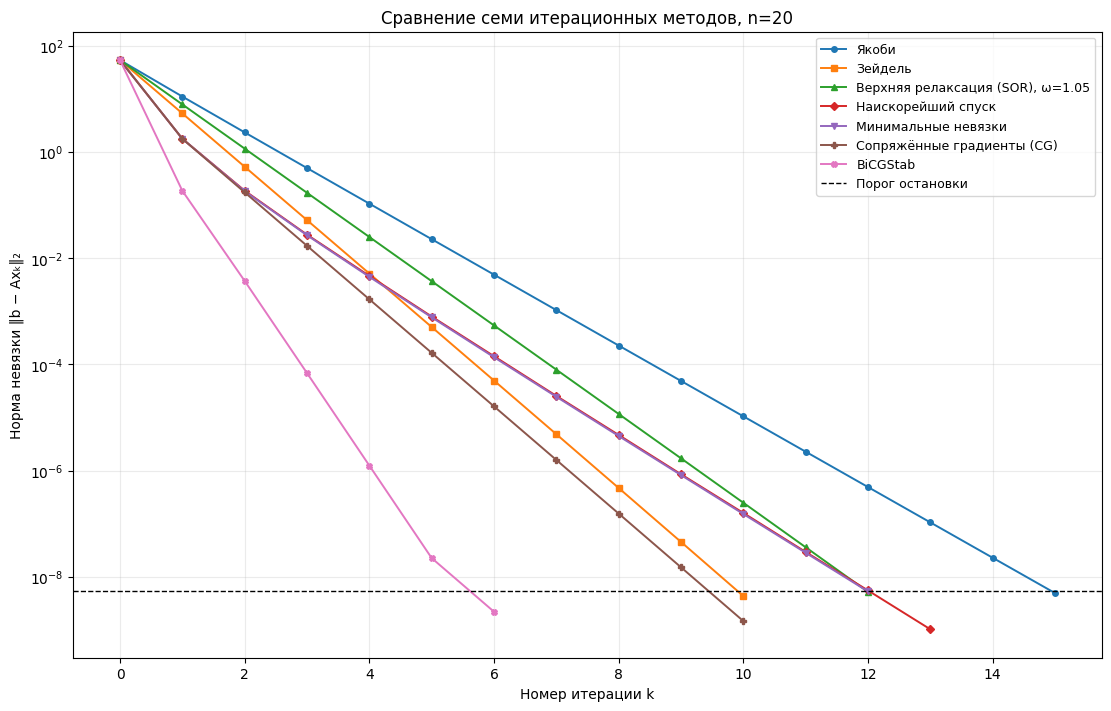

In [6]:
colors = plt.get_cmap("tab10").colors
markers = ("o", "s", "^", "D", "v", "P", "X")
fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
for index, (key, result) in enumerate(iterative_results.items()):
    visible = np.where(result.residuals > 0, result.residuals, np.nan)
    label = METHOD_NAMES[key] + (f", ω={OMEGA:g}" if key == "sor" else "")
    if not result.converged:
        label += f" [{result.status}]"
    ax.semilogy(np.arange(len(visible)), visible, marker=markers[index], markersize=4,
                color=colors[index], linewidth=1.4, label=label)
ax.axhline(TARGET, color="black", linestyle="--", linewidth=1, label="Порог остановки")
ax.set(xlabel="Номер итерации k", ylabel="Норма невязки ‖b − Axₖ‖₂",
       title=f"Сравнение семи итерационных методов, n={len(b)}")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=9)
fig.savefig(FIGURES / "convergence_all.png", dpi=160)
plt.show()
plt.close(fig)

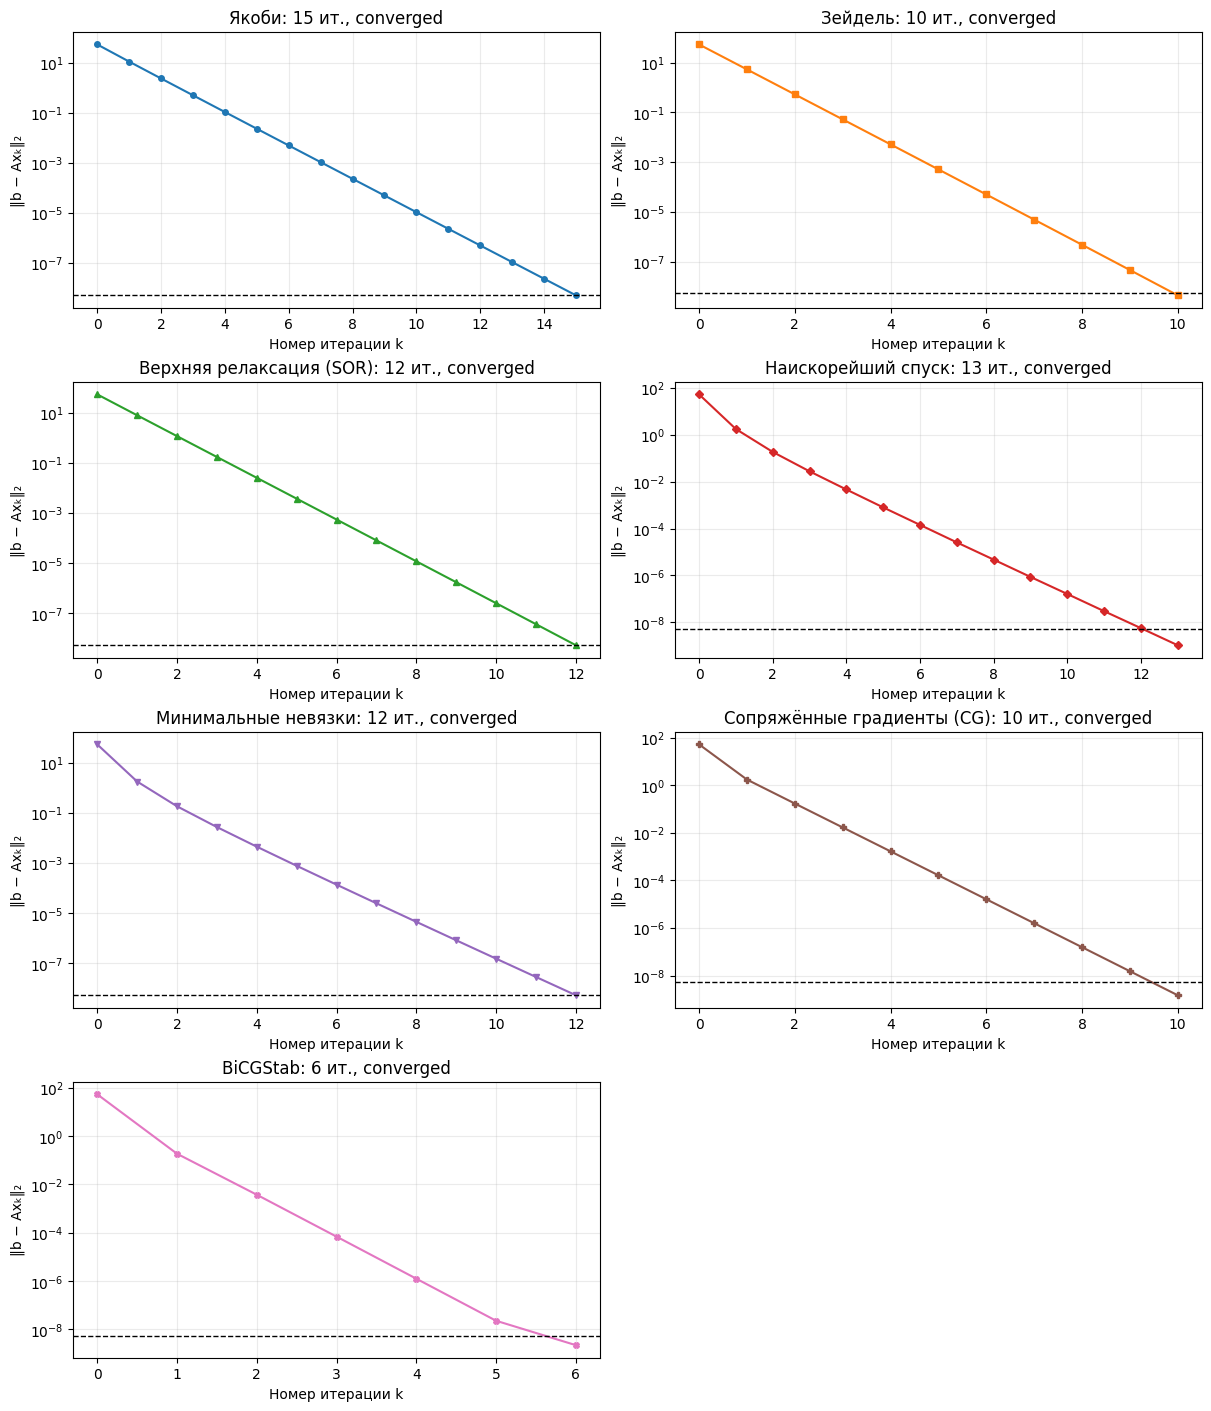

In [7]:
# Отдельные панели позволяют рассмотреть близкие линии.
fig, axes = plt.subplots(4, 2, figsize=(12, 14), layout="constrained")
for index, ((key, result), ax) in enumerate(zip(iterative_results.items(), axes.flat)):
    visible = np.where(result.residuals > 0, result.residuals, np.nan)
    ax.semilogy(np.arange(len(visible)), visible, marker=markers[index], color=colors[index], markersize=4)
    ax.axhline(TARGET, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"{METHOD_NAMES[key]}: {result.iterations} ит., {result.status}",
           xlabel="Номер итерации k", ylabel="‖b − Axₖ‖₂")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(True, which="both", alpha=0.25)
axes.flat[-1].axis("off")
fig.savefig(FIGURES / "convergence_individual.png", dpi=160)
plt.show()
plt.close(fig)

## 5. Влияние параметра верхней релаксации

Сравним несколько фиксированных значений $\omega$, включая $\omega=1$ (метод Зейделя).
Все остальные параметры одинаковы. Исследование не подменяет основной запуск с `OMEGA`.
Даже для SPD-матрицы условие $1<\omega<2$ гарантирует сходимость, но **не ускорение**
по сравнению с Зейделем. На этой хорошо обусловленной системе слишком большое
$\omega$ может замедлять процесс. Для иной матрицы результат может измениться.

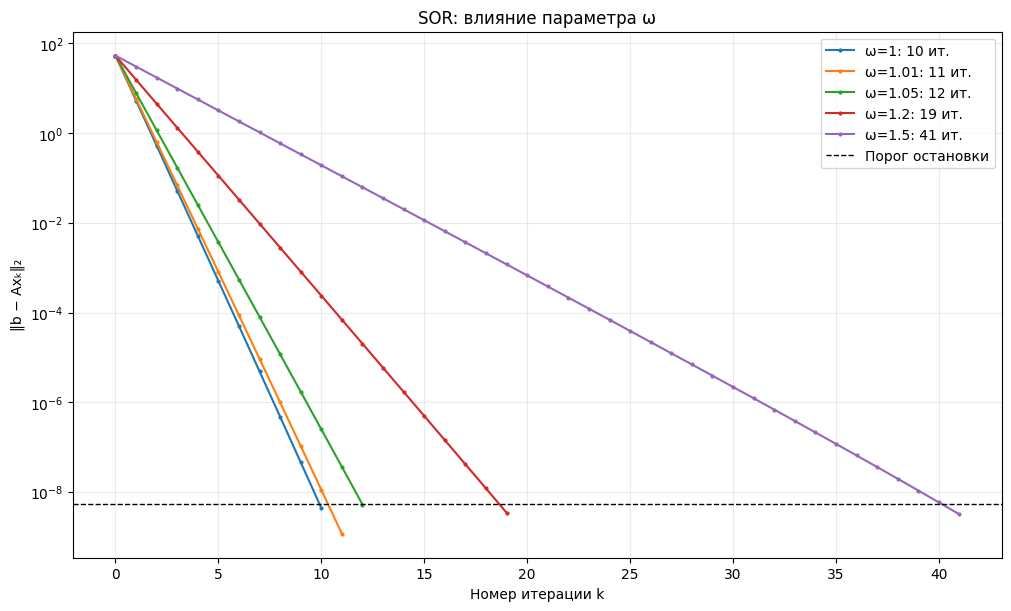

| ω | ρ(B_SOR) | Итерации | Статус |
|---:|---:|---:|---|
| 1 | 0.0288566 | 10 | converged |
| 1.01 | 0.0255445 | 11 | converged |
| 1.05 | 0.0601683 | 12 | converged |
| 1.2 | 0.209186 | 19 | converged |
| 1.5 | 0.507108 | 41 | converged |

In [8]:
omega_values = sorted(set([1.0, 1.01, 1.05, 1.2, 1.5, OMEGA]))
sor_results = {w: iterate(A, b, "sor", x0=X0, rtol=RTOL, atol=ATOL, max_iter=MAX_ITER, omega=w)
               for w in omega_values}
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
table = ["| ω | ρ(B_SOR) | Итерации | Статус |", "|---:|---:|---:|---|"]
for w, result in sor_results.items():
    visible = np.where(result.residuals > 0, result.residuals, np.nan)
    ax.semilogy(np.arange(len(visible)), visible, marker=".", markersize=4, label=f"ω={w:g}: {result.iterations} ит.")
    rho = diagnostics(A, w)["rho_sor"]
    rho_text = f"{rho:.6g}" if rho is not None else "—"
    table.append(f"| {w:g} | {rho_text} | {result.iterations} | {result.status} |")
ax.axhline(TARGET, color="black", linestyle="--", linewidth=1, label="Порог остановки")
ax.set(xlabel="Номер итерации k", ylabel="‖b − Axₖ‖₂", title="SOR: влияние параметра ω")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.savefig(FIGURES / "sor_parameter.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("\n".join(table)))

## 6. Проверка и выводы

Следующая ячейка проверяет соответствие итоговой сохранённой невязки реальному
вектору решения и выполнение критерия у всех методов со статусом `converged`.
Дополнительные автоматические тесты алгоритмов находятся в `test_solvers.py`.

In [9]:
for key, result in iterative_results.items():
    actual = np.linalg.norm(b - A @ result.x)
    np.testing.assert_allclose(result.residuals[-1], actual, rtol=1e-12, atol=1e-14)
    if result.converged:
        assert actual <= TARGET, key
converged = {key: result for key, result in iterative_results.items() if result.converged}
print(f"Сошлось итерационных методов: {len(converged)} из {len(iterative_results)}")
if converged:
    best = min(result.iterations for result in converged.values())
    names = [METHOD_NAMES[key] for key, result in converged.items() if result.iterations == best]
    print(f"Меньше всего итераций ({best}): {', '.join(names)}.")
if iterative_results["gauss_seidel"].converged and iterative_results["sor"].converged:
    print(f"Зейдель: {iterative_results['gauss_seidel'].iterations} ит.; "
          f"SOR при ω={OMEGA:g}: {iterative_results['sor'].iterations} ит.")
print("Все проверки итоговых невязок выполнены.")

Сошлось итерационных методов: 7 из 7
Меньше всего итераций (6): BiCGStab.
Зейдель: 10 ит.; SOR при ω=1.05: 12 ит.
Все проверки итоговых невязок выполнены.


- Прямые методы дают решение с ошибками округления; итерационные останавливаются
  при достижении заданного допуска. Это разные критерии завершения.
- Для исходного варианта **м)** диагональное преобладание и положительная
  определённость обеспечивают применимость перечисленных классических схем.
  Небольшое $\kappa_2(A)$ согласуется с быстрой сходимостью и малой чувствительностью решения.
- Градиентный спуск минимизирует квадратичный функционал вдоль направления,
  метод минимальных невязок — норму невязки вдоль того же направления.
  CG использует сопряжённые направления, BiCGStab — стабилизированные бисопряжённые.
- Убывание евклидовой нормы невязки не обязано быть монотонным у всех методов.
  Поэтому возможные колебания не следует сглаживать или удалять из графика.
- Число итераций зависит от системы, начального приближения и допуска.
  Вывод о скорости по одной СЛАУ нельзя переносить на произвольные матрицы;
  одна итерация разных методов имеет разную вычислительную стоимость.

## Источники

1. **Практикум Аристовой, Лобанова, Завьяловой**, II.10.5, м), стр. 69
   (70-я страница присланного PDF): исходные коэффициенты системы.
2. **«Итерационные методы решения системы линейных алгебраических уравнений»**
   (`1_2_Iteratsionnye_metody_reshenia_sistemy_lineynykh_algebraicheskikh.pdf`),
   §3.1.1–3.1.2, стр. 80–85; §3.2.2, стр. 87–88;
   §3.4.5, стр. 115–116; §3.4.8.2, стр. 120–121:
   стационарные итерации, наискорейший спуск, BiCGStab и CG.
3. **В. В. Пузикова. «Решение систем линейных алгебраических уравнений методом
   BiCGStab с предобусловливанием»**, 2011, стр. 124–125
   (страницы 1–2 присланного PDF): базовая схема BiCGStab.
   Здесь используется вариант без предобусловливания.

Формула одномерного метода минимальных невязок выведена выше непосредственно
из минимизации $\|r-\alpha Ar\|_2^2$.